# Phúc · U-Net++ và deep supervision

Xem sơ đồ nested dense skip, chạy forward của hai cấu hình B/C và đọc điểm từng head của C đã lưu trong đồ án.

Notebook đã lưu sẵn bảng và hình. Để chạy lại, chọn kernel Python của đồ án trong VS Code hoặc Jupyter rồi bấm **Run All**. Môi trường dùng các gói trong [requirements.txt](../../../requirements.txt) và [requirements-notebook.txt](../../../requirements-notebook.txt).

In [1]:
from pathlib import Path
import json
import sys

cwd = Path.cwd().resolve()
candidates = (cwd, *cwd.parents, cwd / "unet-vs-unetplusplus-polyp")
root = next(
    (folder for folder in candidates if (folder / "project.py").is_file()
     and (folder / "configs" / "protocol_lock.json").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError("Mở notebook từ thư mục đồ án hoặc thư mục members/<tên>/works_done.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
colors = {"A": "#345e86", "B": "#b76b21", "C": "#187c70"}

def read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))

from PIL import Image as PILImage

def show_saved_image(path, max_width=1050, max_height=650):
    with PILImage.open(path) as image:
        image.thumbnail((max_width, max_height), PILImage.Resampling.LANCZOS)
        display(image)

## Các node và đường nối

[unetplusplus.py](unetplusplus.py) định nghĩa 15 node trên năm độ phân giải. Node X(i,j) với j > 0 nối theo chiều kênh các node cùng mức X(i,0)…X(i,j−1) và tensor upsample từ X(i+1,j−1). [architecture_figures.py](architecture_figures.py) tạo sơ đồ bên dưới.

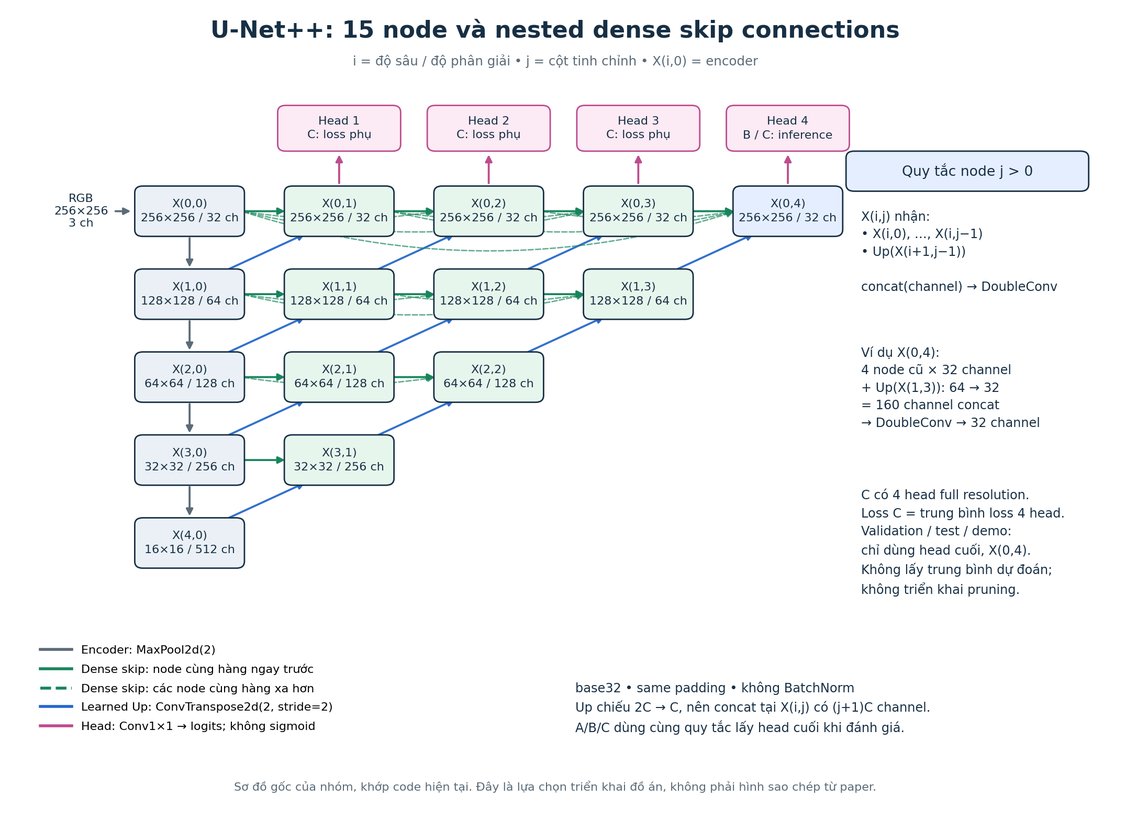

In [2]:
show_saved_image(root / "members/phuc/works_done/artifacts/architecture/unetplusplus_course_topology.png",
                 max_width=1350, max_height=820)

## Forward B và C

B trả logits từ X(0,4). C trả bốn tensor logits theo thứ tự X(0,1) đến X(0,4). Các lệnh hook ghi shape đầu ra của 15 node và số kênh thực tế ngay trước DoubleConv ở mỗi node nested. Phép chạy dùng tensor đầu vào 256×256 và trọng số khởi tạo.

In [3]:
import torch

from members.duy.works_done.unet import count_parameters
from members.phuc.works_done.unetplusplus import NestedSkipBlock, UNetPlusPlus

torch.set_num_threads(2)
cfg_b = read_json(root / "configs/unetplusplus.json")
cfg_c = read_json(root / "configs/unetplusplus_ds.json")
image = torch.zeros(1, cfg_c["model_kwargs"]["in_channels"], *cfg_c["image_size"])
model_b = UNetPlusPlus(**cfg_b["model_kwargs"]).eval()
model_c = UNetPlusPlus(**cfg_c["model_kwargs"]).eval()
features, joined_channels = {}, {}

def record_feature(name):
    def hook(_module, _inputs, output):
        features[name] = tuple(output.shape)
    return hook

def record_concat(name):
    def hook(_module, inputs):
        joined_channels[name] = inputs[0].shape[1]
    return hook

hooks = []
for name, module in model_c.named_children():
    if name.startswith("conv"):
        hooks.append(module.register_forward_hook(record_feature(name)))
    if isinstance(module, NestedSkipBlock):
        hooks.append(module.conv.register_forward_pre_hook(record_concat(name)))
try:
    with torch.inference_mode():
        logits_b = model_b(image)
        logits_c = model_c(image)
finally:
    for handle in hooks:
        handle.remove()

display(pd.DataFrame([
    {"Mô hình": "B", "Tham số": count_parameters(model_b), "Số head": 1, "Shape mỗi head": tuple(logits_b.shape)},
    {"Mô hình": "C", "Tham số": count_parameters(model_c), "Số head": len(logits_c), "Shape mỗi head": tuple(logits_c[-1].shape)},
]).set_index("Mô hình"))

,Tham số,Số head,Shape mỗi head
Mô hình,,,
B,9042177,1,"(1, 1, 256, 256)"
C,9042276,4,"(1, 1, 256, 256)"


,Kênh trước DoubleConv (nested),Kênh đầu ra,H × W
Node,,,
"X(0,0)",—,32,256 × 256
"X(1,0)",—,64,128 × 128
"X(2,0)",—,128,64 × 64
"X(3,0)",—,256,32 × 32
"X(4,0)",—,512,16 × 16
"X(0,1)",64,32,256 × 256
"X(1,1)",128,64,128 × 128
"X(2,1)",256,128,64 × 64
"X(3,1)",512,256,32 × 32


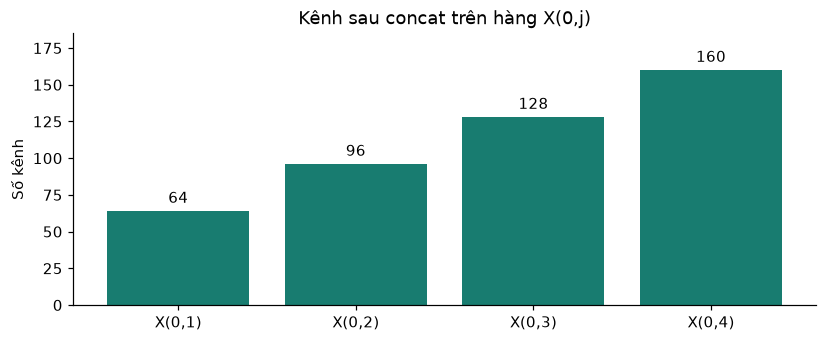

In [4]:
node_rows = []
for name, shape in features.items():
    depth, column = map(int, name.removeprefix("conv").split("_"))
    node_rows.append({
        "Node": f"X({depth},{column})",
        "Kênh trước DoubleConv (nested)": joined_channels.get(name, "—"),
        "Kênh đầu ra": shape[1],
        "H × W": f"{shape[2]} × {shape[3]}",
    })
nodes = pd.DataFrame(node_rows)
display(nodes.set_index("Node"))

top_nodes = nodes[nodes["Node"].isin(["X(0,1)", "X(0,2)", "X(0,3)", "X(0,4)"])]
fig, ax = plt.subplots(figsize=(7.4, 3), layout="constrained")
bars = ax.bar(top_nodes["Node"], top_nodes["Kênh trước DoubleConv (nested)"].astype(int), color=colors["C"])
ax.bar_label(bars, padding=3)
ax.set(title="Kênh sau concat trên hàng X(0,j)", ylabel="Số kênh", ylim=(0, 185))
plt.show()

X(0,2) nhận hai tensor trước và một tensor upsample, tạo 3 × 32 = 96 kênh trước DoubleConv. X(0,4) nhận tổng cộng năm tensor, tương ứng 160 kênh. Mỗi node trên hàng đầu đưa 32 kênh ra.

## Chất lượng từng head của C

Số liệu bổ sung do [submission_analysis.py](../../tri/works_done/submission_analysis.py) xuất từ checkpoint C cố định. `mean` là trung bình xác suất của bốn head trước khi threshold. Bảng A/B/C chính dùng head 4 cho C.

val            test        
        dice     iou    dice     iou
head                                
1     0.3676  0.2490  0.3328  0.2242
2     0.5862  0.4404  0.5606  0.4194
3     0.7676  0.6545  0.7268  0.6100
4     0.7888  0.6845  0.7390  0.6304
mean  0.7701  0.6603  0.7183  0.6091

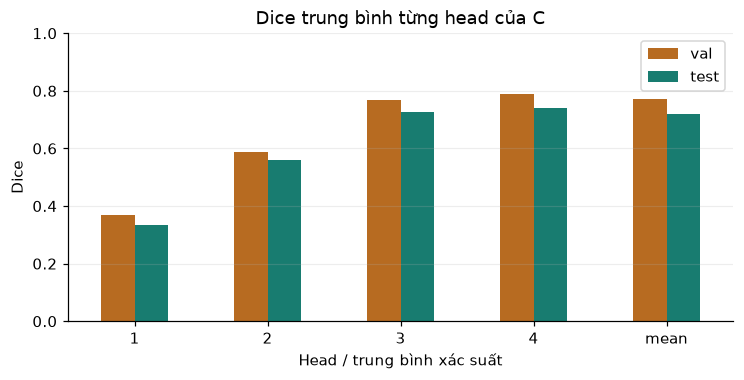

In [5]:
evidence = root / "results/report_figures/checklist_20261114"
head_tables = {
    split: pd.read_csv(evidence / f"head_metrics_{split}.csv", dtype={"head": str}).set_index("head")
    for split in ("val", "test")
}
head_scores = pd.concat({key: table[["dice", "iou"]] for key, table in head_tables.items()}, axis=1)
display(head_scores.round(4))

ax = head_scores.xs("dice", level=1, axis=1).plot.bar(
    color=[colors["B"], colors["C"]], figsize=(7.8, 3.4), rot=0, ylim=(0, 1),
)
ax.set(title="Dice trung bình từng head của C", xlabel="Head / trung bình xác suất", ylabel="Dice")
ax.grid(axis="y", alpha=0.22)
plt.show()